In [66]:
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Same 16 terms as step 3 (by_party / aligned_divergence). They are also the
# phrasing protect set below, so this list must match step 3's TARGET_TERMS or
# the counts come from a different token stream than the models train on.
TARGET_TERMS = [
    'fraud', 'integrity', 'security', 'voter',
    'ballot', 'election', 'certification', 'audit',
    'stolen', 'rigged', 'access', 'mail',
    'illegal', 'legitimate', 'trust', 'transparency',
]

DATA_PATH = './filtered_outputs/all_filtered_combined.csv'
COUNTS_CACHE = './filtered_outputs/term_mentions_by_party.csv'
FIG_PATH = './shared_figures/term_usage_by_party.jpg'

DEM, REP = '#3498db', '#e74c3c'   # repo party palette (CVD-validated)


def label_axes(fig, axes, xlabel, ylabel, gap=0.08, **text_kw):
    """Shared x/y labels placed `gap` inches outside the panels' tick labels.

    Call after tight_layout(). fig.supxlabel/supylabel default to fixed figure
    coordinates, so the gap to the tick labels changed with every figure size.
    """
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    boxes = [ax.get_tightbbox(renderer) for ax in axes if ax.get_visible()]
    to_fig = fig.transFigure.inverted()
    gap_px = gap * fig.dpi
    left = to_fig.transform((min(b.x0 for b in boxes) - gap_px, 0))[0]
    bottom = to_fig.transform((0, min(b.y0 for b in boxes) - gap_px))[1]
    fig.supxlabel(xlabel, y=bottom, va='top', **text_kw)
    fig.supylabel(ylabel, x=left, ha='right', **text_kw)

Saved: ./shared_figures/cross_party_divergence.jpg   (16 terms, 4x4)


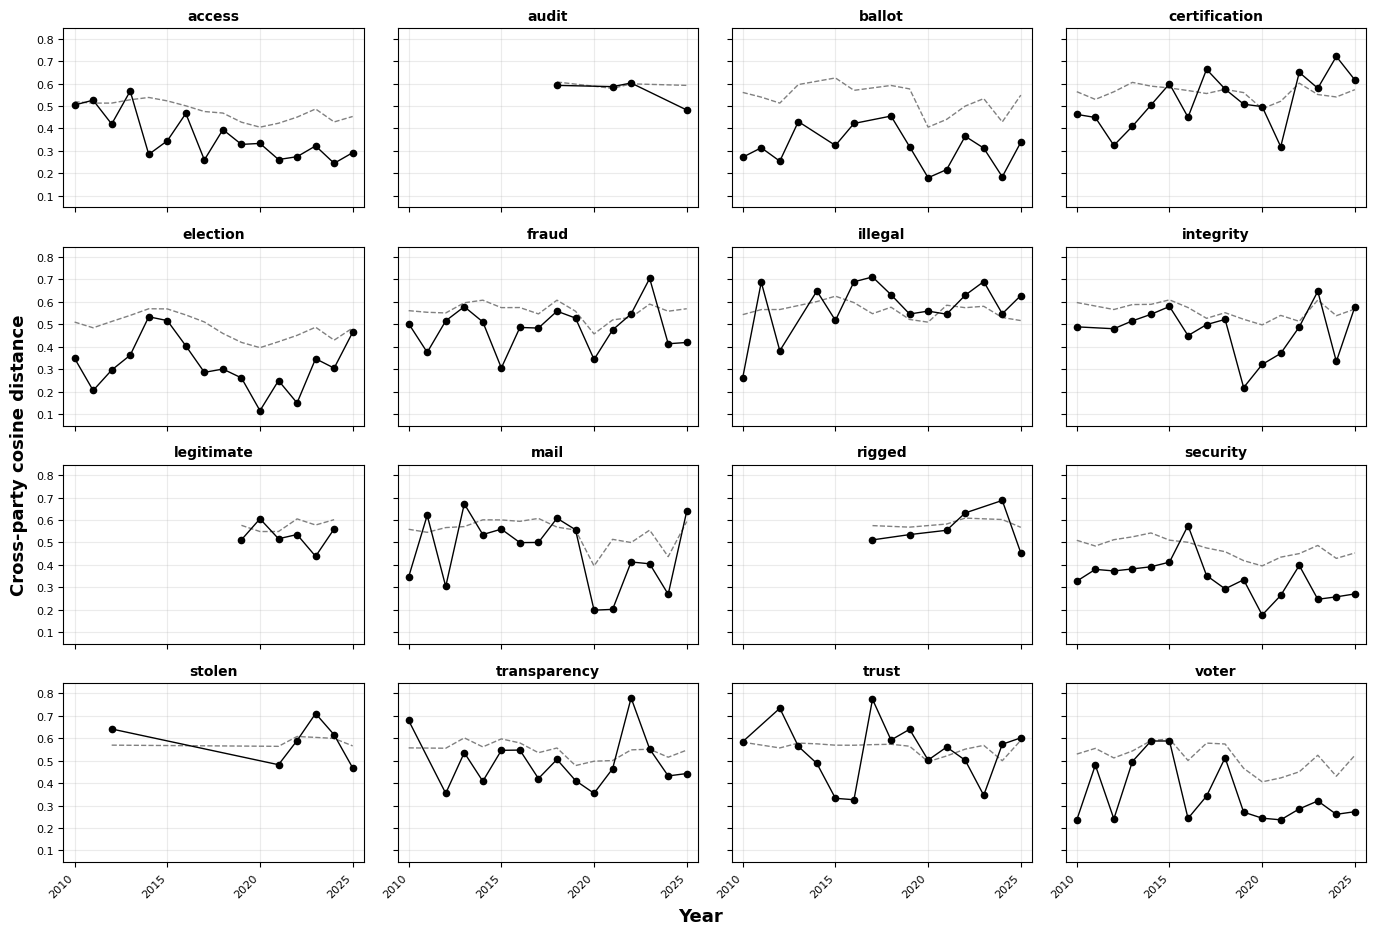

In [67]:
# Caption
# Figure 1. Cross-party divergence over time. Each panel shows one target term’s aligned cosine distance between the two parties’ vectors by year.
# The dashed line is the noise floor (median aligned distance of the 100 frequency-matched shared words). A year is absent when a term is not mentioned at least five times.
DIV_PATH = './filtered_outputs/diachronic/aligned_divergence/seed/42/aligned_divergence.csv'
DIV_FIG = './shared_figures/cross_party_divergence.jpg'
NCOLS = 4


def _integer_period_ticks(xmin, xmax, step=5):
    """Whole-period tick positions (kills matplotlib's '2012.5' auto-ticks)."""
    ticks = list(range(int(xmin), int(xmax) + 1, step))
    if ticks and ticks[-1] != int(xmax):
        ticks.append(int(xmax))
    return ticks


div_df = pd.read_csv(DIV_PATH)

# Alphabetical, keeping terms with >=2 observed years so a line can be drawn.
order = sorted(t for t in div_df['term'].unique()
               if (div_df['term'] == t).sum() >= 2)
n = len(order)
nrows = int(np.ceil(n / NCOLS))

# Shared, data-driven limits: every panel on one scale, so panel-to-panel
# height differences are real differences in divergence. Both axes carry a
# margin past the data — without it the 2010 and 2025 markers sit exactly on
# the left/right spines and the top marker on the upper spine, so each is
# drawn half-clipped.
ymin = float(min(div_df['divergence_aligned'].min(), div_df['freq_matched_median'].min()))
ymax = float(max(div_df['divergence_aligned'].max(), div_df['freq_matched_median'].max()))
ypad = (ymax - ymin) * 0.10
xmin = int(div_df['period'].min())
xmax = int(div_df['period'].max())
xpad = 0.6                       # years of margin; keeps the end dots whole
xticks = _integer_period_ticks(xmin, xmax, step=5)

fig, axes = plt.subplots(nrows, NCOLS, figsize=(NCOLS * 3.4, nrows * 2.3),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for i, term in enumerate(order):
    ax = axes[i]
    td = div_df[div_df['term'] == term].sort_values('period')
    # Monochrome: one series per panel, so color would carry no information.
    # NOTE: a term absent in a year (missed min_count=5 in one party) leaves no
    # row, and the line connects straight across the gap — `stolen` therefore
    # appears to run continuously from 2012 to 2020. Markers show the years
    # actually observed.
    ax.plot(td['period'], td['divergence_aligned'], marker='o', color='0',
            linewidth=1, markersize=4.5, zorder=3)
    ax.plot(td['period'], td['freq_matched_median'], linestyle='--',
        color='0.5', linewidth=1, zorder=2)

    ax.set_title(term, fontsize=10, fontweight='bold')
    ax.set_xlim(xmin - xpad, xmax + xpad)
    ax.set_ylim(ymin - ypad, ymax + ypad)
    ax.set_xticks(xticks)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=8)

for ax in axes[:n]:
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

# Hide any unused trailing panels (16 terms fill a 4x4 exactly; this keeps the
# cell correct if a term drops out of the CSV).
for j in range(n, len(axes)):
    axes[j].axis('off')

# No suptitle: the figure is titled by its LaTeX caption in the manuscript, and
# repeating it inside the image duplicates it on the page.
plt.tight_layout()
label_axes(fig, axes, 'Year', 'Cross-party cosine distance',
           fontsize=13, fontweight='bold')

os.makedirs(os.path.dirname(DIV_FIG), exist_ok=True)
plt.savefig(DIV_FIG, dpi=1200, bbox_inches='tight', pad_inches=0.3,
            pil_kwargs={'quality': 95})
print(f'Saved: {DIV_FIG}   ({n} terms, {nrows}x{NCOLS})')
plt.show()


Saved: ./shared_figures/cross_party_divergence_percentile.jpg   (16 terms, 4x4)


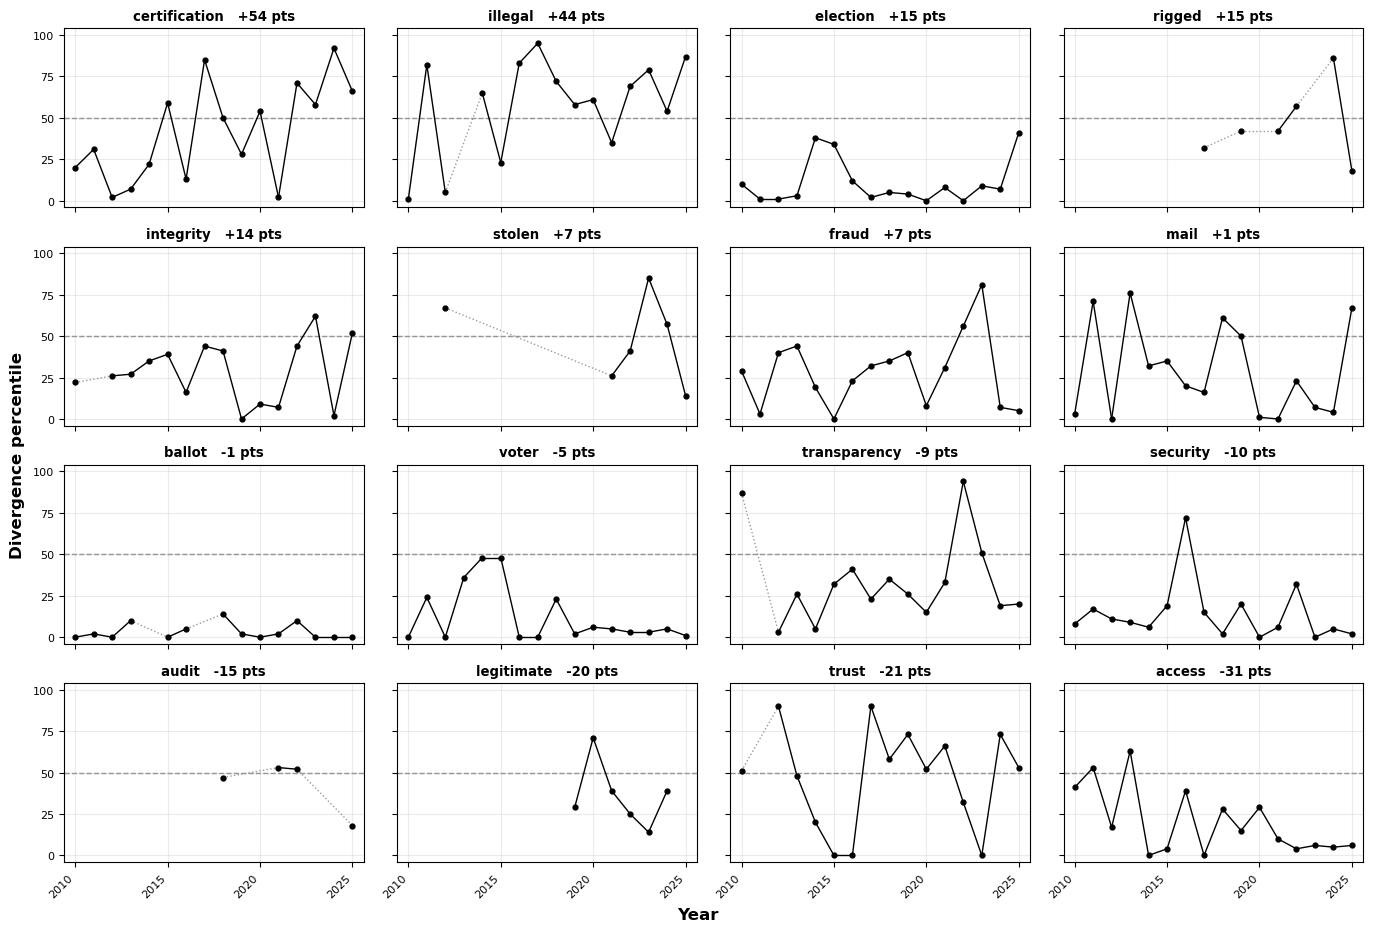

In [68]:
# Caption
# Figure 2. Cross-party divergence percentile over time.
# Each panel shows a term’s divergence percentile among the 100 frequency-matched shared words that year;
# a term at 90 is more divergent than 90% of comparable words. Dotted lines indicate a term fell below the five-occurrence minimum.
# Panels are ordered by the change shown beside each term (mean of last three observed years minus mean of first three).
PCT_FM_FIG = './shared_figures/cross_party_divergence_percentile.jpg'
PCT_COL = 'percentile_vs_freq_matched'
EARLY_LATE_K = 3        # years averaged at each end to measure the change

div_df = pd.read_csv(DIV_PATH)


def early_late_change(values):
    """Mean of the last k observed years minus the mean of the first k.

    k shrinks to n//2 for short series so the two windows never OVERLAP — with
    only 4 observations, a fixed k=3 would count the middle two years in both
    the 'early' and the 'late' mean and understate the change. (`audit`, n=4,
    is the term this rule exists for: k=2 gives -17 pts, an overlapping k=3
    would report -11.)
    """
    k = max(1, min(EARLY_LATE_K, len(values) // 2))
    return sum(values[-k:]) / k - sum(values[:k]) / k


# Order by early->late change in the matched percentile; ties alphabetical.
changes = {}
for term, g in div_df.groupby('term'):
    vals = g.sort_values('period')[PCT_COL].tolist()
    if len(vals) >= 2:
        changes[term] = early_late_change(vals)
order = sorted(changes, key=lambda t: (-changes[t], t))

n = len(order)
NCOLS = 4
nrows = int(np.ceil(n / NCOLS))

xmin = int(div_df['period'].min())
xmax = int(div_df['period'].max())
xpad = 0.6                       # keeps the 2010 and 2025 markers off the spines
xticks = _integer_period_ticks(xmin, xmax, step=5)

fig, axes = plt.subplots(nrows, NCOLS, figsize=(NCOLS * 3.4, nrows * 2.3),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for i, term in enumerate(order):
    ax = axes[i]
    td = div_df[div_df['term'] == term].sort_values('period')
    yrs = td['period'].tolist()
    vals = td[PCT_COL].tolist()

    # 50 = the median of this term's frequency-matched words that year.
    ax.axhline(50, color='0.55', ls='--', lw=1, zorder=1)

    # Dotted gray across missing years (term missed min_count in one party).
    for (y1, v1), (y2, v2) in zip(zip(yrs, vals), zip(yrs[1:], vals[1:])):
        adjacent = (y2 - y1) == 1
        ax.plot([y1, y2], [v1, v2], color='0' if adjacent else '0.6',
                ls='-' if adjacent else ':', lw=1, zorder=3 if adjacent else 2)
    ax.plot(yrs, vals, ls='none', marker='o', ms=3.5, color='0', zorder=4)

    ax.set_title(f'{term}   {changes[term]:+.0f} pts', fontsize=9.5,
                 fontweight='bold')
    ax.set_xlim(xmin - xpad, xmax + xpad)
    ax.set_ylim(-4, 104)
    ax.set_xticks(xticks)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=8)

for ax in axes[:n]:
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
for j in range(n, len(axes)):
    axes[j].axis('off')

# No suptitle: the figure is titled by its LaTeX caption in the manuscript.
plt.tight_layout()
label_axes(fig, axes, 'Year', 'Divergence percentile',
           fontsize=12, fontweight='bold')

os.makedirs(os.path.dirname(PCT_FM_FIG), exist_ok=True)
plt.savefig(PCT_FM_FIG, dpi=1200, bbox_inches='tight', pad_inches=0.3,
            pil_kwargs={'quality': 95})
print(f'Saved: {PCT_FM_FIG}   ({n} terms, {nrows}x{NCOLS})')
plt.show()

In [69]:
# ---- Count mentions per (term, year, party) — cached ------------------------
# Identical preprocessing + protected phrasing to step 3, so a
# 'mention' here is a post-preprocessing standalone token, the same unit
# Word2Vec trains on and the same unit in divergence_symmetry.csv's
# dem_mentions/rep_mentions columns.
if os.path.exists(COUNTS_CACHE):
    counts = pd.read_csv(COUNTS_CACHE)
    print(f'Loaded cached counts: {COUNTS_CACHE} ({len(counts)} rows)')
else:
    import nltk
    from nltk.tokenize import word_tokenize
    from nltk.corpus import stopwords
    from gensim.models.phrases import Phrases
    nltk.download('punkt', quiet=True)
    nltk.download('punkt_tab', quiet=True)
    nltk.download('stopwords', quiet=True)

    stop_words = set(stopwords.words('english'))
    stop_words.update({'would','could','should','may','might','must','said','says',
        'say','told','tell','get','got','getting','make','made','making','one','two',
        'three','first','second','last','also','however','therefore','thus','us','amp',
        'http','https','www'})

    def preprocess_text(text):
        if pd.isna(text): return []
        return [t for t in word_tokenize(str(text).lower())
                if t.isalpha() and len(t) > 2 and t not in stop_words]

    df = pd.read_csv(DATA_PATH)
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    df['year'] = df['Date'].dt.year
    df = df[df['Party'].isin(['Democrat', 'Republican'])].dropna(subset=['year']).copy()
    df['year'] = df['year'].astype(int)

    print('Tokenizing (slow part, ~2 min) ...')
    df['tokens'] = df['Body_Subject'].apply(preprocess_text)
    df = df[df['tokens'].str.len() >= 10].copy()
    big = Phrases(df['tokens'].tolist(), min_count=5, threshold=10, delimiter='_')
    tri = Phrases([big[t] for t in df['tokens']], min_count=5, threshold=10, delimiter='_')

    # Undo any merge that swallows a target term (same rule as step 3).
    protect = set(TARGET_TERMS)
    def phrase(tokens):
        out = []
        for tok in tri[big[tokens]]:
            parts = tok.split('_')
            out.extend(parts if any(p in protect for p in parts) else [tok])
        return out
    df['tf'] = df['tokens'].apply(phrase)

    rows = []
    for (year, party), grp in df.groupby(['year', 'Party']):
        c = Counter()
        for toks in grp['tf']:
            c.update(toks)
        for term in TARGET_TERMS:
            rows.append({'term': term, 'year': year, 'party': party,
                         'mentions': c.get(term, 0)})
    counts = pd.DataFrame(rows)
    counts.to_csv(COUNTS_CACHE, index=False)
    print(f'Counted + cached -> {COUNTS_CACHE}')

counts.head()

Loaded cached counts: ./filtered_outputs/term_mentions_by_party.csv (512 rows)


,term,year,party,mentions
0,fraud,2010,Democrat,23
1,integrity,2010,Democrat,8
2,security,2010,Democrat,89
3,voter,2010,Democrat,30
4,ballot,2010,Democrat,14


Saved: ./shared_figures/term_usage_by_party.jpg


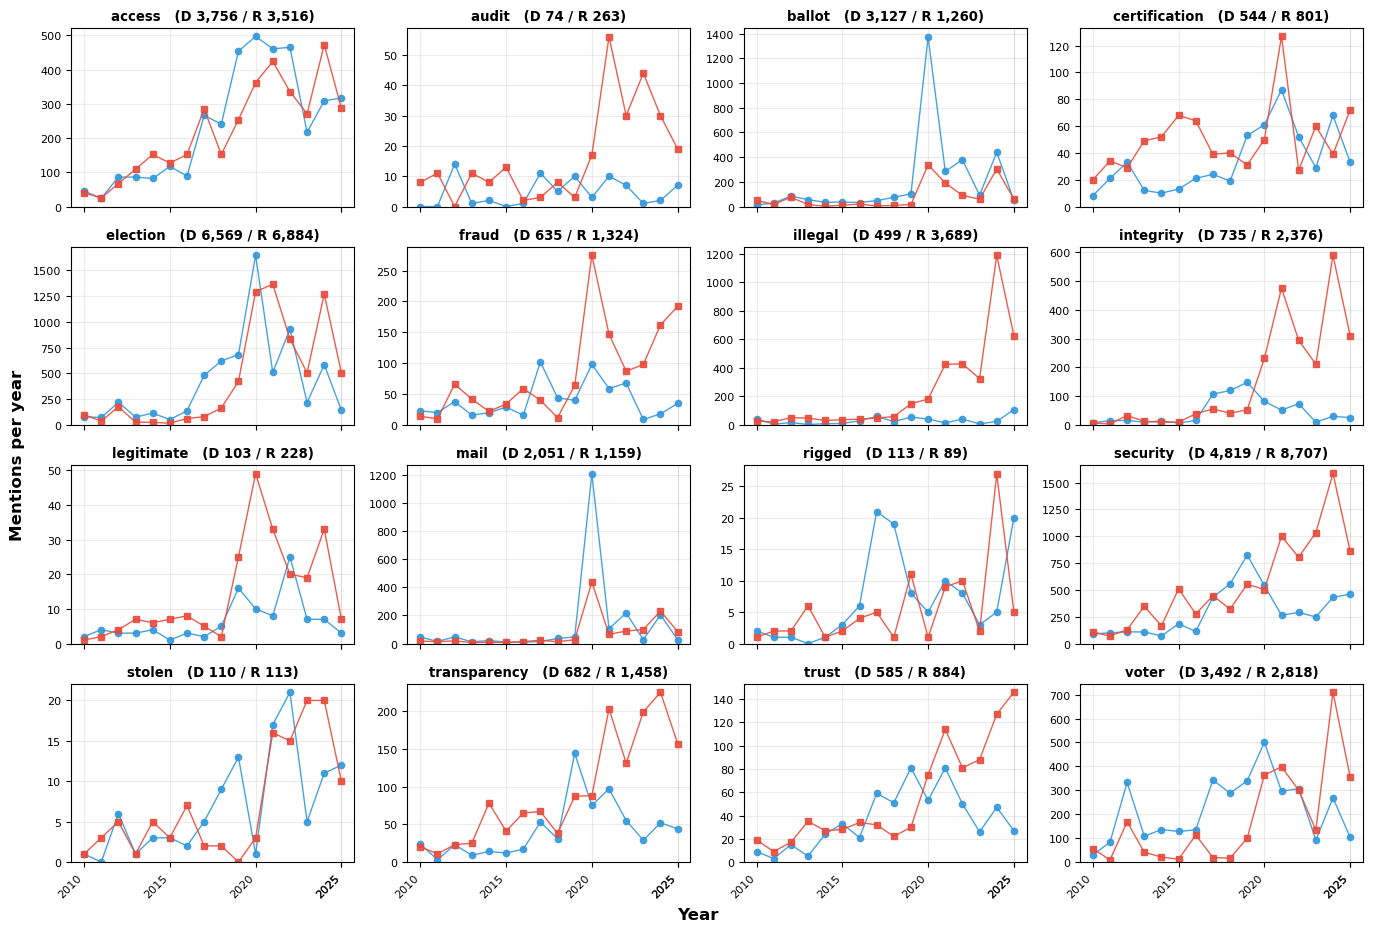

In [ ]:
# Caption
# Figure 3. Term frequency by party over time.  
# Term frequency by party and year (blue, Democratic; 
# red, Republican), with each party’s total shown beside the term.

# order terms alphabetically
order = sorted(counts['term'].unique())
years = sorted(counts['year'].unique())
xticks = [y for y in years if y % 5 == 0] + [years[-1]]

fig, axes = plt.subplots(4, 4, figsize=(13.6, 9.2), sharex=True)
axes = axes.ravel()

for i, term in enumerate(order):
    ax = axes[i]
    td = counts[counts['term'] == term]
    for party, color, marker in [('Democrat', DEM, 'o'), ('Republican', REP, 's')]:
        s = (td[td['party'] == party].set_index('year')['mentions']
             .reindex(years, fill_value=0))
        ax.plot(s.index, s.values, color=color, marker=marker,
                markersize=4.5, linewidth=1, alpha=0.9)
    d_tot = int(td[td['party'] == 'Democrat']['mentions'].sum())
    r_tot = int(td[td['party'] == 'Republican']['mentions'].sum())
    ax.set_title(f'{term}   (D {d_tot:,} / R {r_tot:,})', fontsize=9.5,
                 fontweight='bold')
    ax.set_ylim(bottom=0)
    ax.set_xticks(xticks)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=8)

for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
label_axes(fig, axes, 'Year', 'Mentions per year',
           fontsize=12, fontweight='bold')

os.makedirs(os.path.dirname(FIG_PATH), exist_ok=True)
plt.savefig(FIG_PATH, dpi=1200, bbox_inches='tight', pad_inches=0.3,
            pil_kwargs={'quality': 95})
print(f'Saved: {FIG_PATH}')
plt.show()

Saved: ./shared_figures/within_party_shift_over_time.jpg


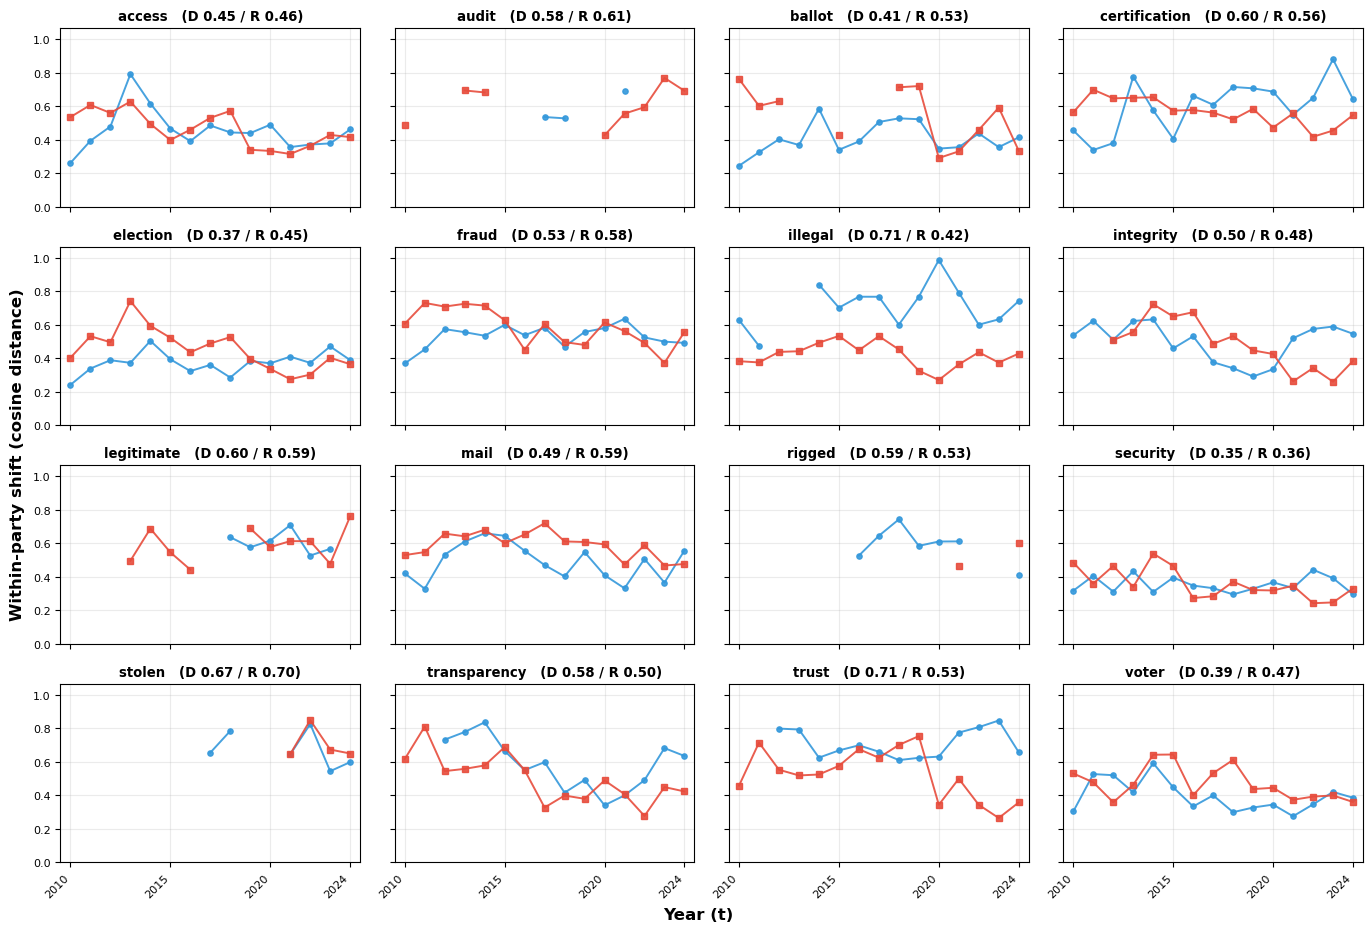

In [75]:
# Caption
# Figure 4. Within-party semantic shift over time. Each point is the cosine distance between
# a party’s vectors for year t and t+1 (blue, Democratic; red, Republican); mean shift per party is shown beside the term. 
SHIFT_PATH = './filtered_outputs/diachronic/by_party/year/42/partisan_semantic_shifts.csv'
SHIFT_FIG = './shared_figures/within_party_shift_over_time.jpg'

sh = pd.read_csv(SHIFT_PATH)
sh['period1'] = sh['period1'].astype(int)
transitions = sorted(sh['period1'].unique())
xticks = [t for t in transitions if t % 5 == 0] + [transitions[-1]]

# ---------------------------------------------------------------- Figure 1
# One panel per term, both parties. Reindexing to the full transition axis
# leaves NaN where a term missed min_count, so the line BREAKS at a gap
# instead of interpolating across it.
terms = sorted(sh['term'].unique())
ncols_s = 4
nrows_s = -(-len(terms) // ncols_s)
ytop = float(sh['shift'].max()) * 1.08

fig, axes = plt.subplots(nrows_s, ncols_s, figsize=(13.6, 2.3 * nrows_s),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, term in zip(axes, terms):
    td = sh[sh['term'] == term]
    means = {}
    for party, color, marker in (('Democrat', DEM, 'o'), ('Republican', REP, 's')):
        s = (td[td['party'] == party].set_index('period1')['shift']
             .reindex(transitions))
        means[party] = s.mean()
        ax.plot(s.index, s.values, color=color, marker=marker, ms=3.8,
                lw=1.4, alpha=0.9)

    d, r = means['Democrat'], means['Republican']
    lab = f"D {d:.2f}" if pd.notna(d) else "D –"
    lab += f" / R {r:.2f}" if pd.notna(r) else " / R –"
    ax.set_title(f'{term}   ({lab})', fontsize=9.5, fontweight='bold')
    ax.set_ylim(0, ytop)
    ax.set_xticks(xticks)
    ax.set_xlim(transitions[0] - 0.5, transitions[-1] + 0.5)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=8)

for ax in axes[len(terms):]:
    ax.set_visible(False)
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')


# fig.suptitle('Within-Party Semantic Movement Over Time', fontsize=16, fontweight='bold')
plt.tight_layout()
label_axes(fig, axes, 'Year (t)', 'Within-party shift (cosine distance)',
           fontsize=12, fontweight='bold')
os.makedirs(os.path.dirname(SHIFT_FIG), exist_ok=True)
plt.savefig(SHIFT_FIG, dpi=1200, bbox_inches='tight', pad_inches=0.5,
            pil_kwargs={'quality': 95})
print(f'Saved: {SHIFT_FIG}')
plt.show()


In [72]:
# ---- Mean within-party shift, term-balanced ----------------------------------
# Source of the draft's "mean shifts of 0.53 for Democrats and 0.52 for
# Republicans": the mean shift per term, then the mean of those 16 term means,
# so heavily observed terms don't dominate. Per-term means (e.g. election
# D 0.37 / R 0.45) are in the panel titles of the figure above.
sh = pd.read_csv(SHIFT_PATH)

per_term = sh.groupby(['party', 'term'])['shift'].mean()
for party in ['Democrat', 'Republican']:
    v = per_term.loc[party]
    print(f'  {party:<11} mean of {len(v)} term-means = {v.mean():.4f}')


  Democrat    mean of 16 term-means = 0.5349
  Republican  mean of 16 term-means = 0.5235


Saved: ./shared_figures/neighbor_overlap_small_multiples.jpg


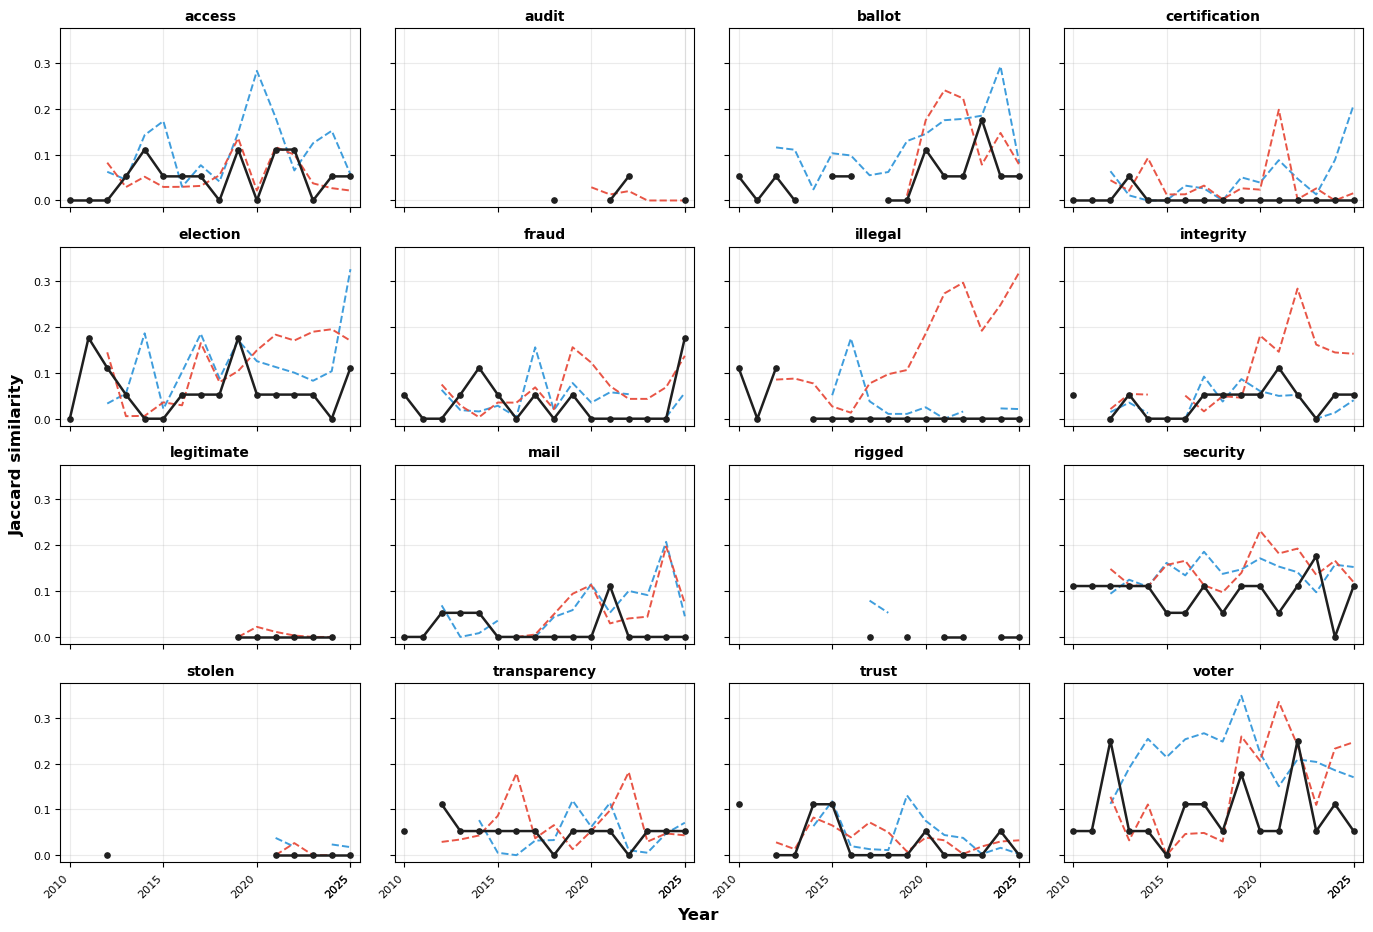

In [73]:
# Caption
# Figure 5. Semantic neighborhood overlap. Each panel tracks one target term’s Jaccard similarity (ranges from 0-1, 
# where 1 is identical neighbors) over time across parties and within each individual party. 
# Jaccard similarity ranges from 0 (completely non-overlapping semantic neighborhoods) to 1 (identical neighbors). 
# Black: cross-party Jaccard similarity of top-10 neighbor sets. Red and blue: within-party split-half baselines. 
# Cross-party overlap below the lower baseline indicates meaningfully non-overlapping neighborhoods.


# ---- Neighbor overlap over time vs. each party's own baseline ---------------
# Small-multiples replacement for neighbor_overlap_timeline.png, which plotted
# all terms on one 0-1 axis: every value lives under 0.25, so the lines were
# crushed into the bottom fifth of the frame and mutually indistinguishable.
#
# Black line: Jaccard of the two parties' top-10 neighbour sets for a term in a
# given year. 0 = the parties share no nearest neighbours; 1 = identical
# neighbourhoods. A year is absent when the term missed min_count=5 in EITHER
# party, so the line breaks rather than interpolating across the gap.
#
# THE TWO BASELINES. Low absolute Jaccard is expected, not evidence of
# polarization: two models trained on two samples of the SAME party already
# disagree on most of their neighbour list. The dashed lines are that floor,
# from step_3_overlap_baseline.py at N_SPLITS=20 -- per (term, year), the
# Jaccard between two disjoint halves of ONE party, averaged over 20 random
# splits, drawn separately for Democrats and Republicans.
#
# WHY SEPARATELY AND NOT POOLED. A pooled floor looks cleaner but is wrong in a
# way that flatters the result. The two parties' floors genuinely differ: on a
# per-cell two-sample test 60% of (term, year) cells exceed |z| = 2, against ~5%
# expected by chance, and the mean |Dem - Rep| floor difference of 0.066 is
# LARGER than the 0.051 mean gap this figure is about. Pooling averages the
# higher party's floor into the reference and overstates the gap.
#
# READ THE LOWER DASHED LINE. The conservative claim is that cross-party
# overlap sits below the lower of the two baselines, i.e. below the lower
# dashed line. That holds in 63% of cells with a mean margin of 0.018. Against
# the pooled floor it would read 87% and 0.050 -- the same direction, roughly
# three times the apparent size. Quote the conservative number.
#
# A FREQUENCY CAVEAT, AND WHY THE LOWER EDGE HANDLES IT. A party's floor tracks
# how often that party uses the term: corr(floor, log10 mentions) = 0.67, and in
# 65% of cells the more talkative party has the higher floor. So an asymmetric
# term would show a large gap against the POOLED floor for reasons that have
# nothing to do with framing. Measured against the lower floor that confound
# disappears -- its correlation with usage asymmetry is 0.055, and the margin is
# flat across asymmetry terciles at 0.016 / 0.017 / 0.020.
#
# 2011 has no baseline: it fell under MIN_DOCS_PER_GROUP=40 and was excluded.
OVERLAP_PATH  = './filtered_outputs/diachronic/by_party/year/42/neighbor_overlap.csv'
BASELINE_PATH = './filtered_outputs/diachronic/overlap_baseline/year/overlap_baseline.csv'
OVERLAP_FIG   = './shared_figures/neighbor_overlap_small_multiples.jpg'

CROSS = '#1f1f1f'   # the measured cross-party signal; ink, so it stays dominant
# DEM / REP come from the setup cell: '#3498db' / '#e74c3c', CVD-validated.

# Black line: full-corpus Dem vs Rep top-10 Jaccard -- the same models and
# neighbour lists as the network figures, so the two always agree.
ov = pd.read_csv(OVERLAP_PATH)
ov['period'] = ov['period'].astype(int)

# Dashed lines: each party's split-half floor, averaged over the 20 splits.
bl = pd.read_csv(BASELINE_PATH)
bl['period'] = bl['period'].astype(int)
fl = (bl[bl['comparison'].isin(['within_dem', 'within_rep'])]
      .groupby(['term', 'period', 'comparison'])['jaccard'].mean().unstack())

ov_years  = sorted(ov['period'].unique())
ov_xticks = [y for y in ov_years if y % 5 == 0] + [ov_years[-1]]
ov_terms  = sorted(ov['term'].unique())

ncols_o = 4
nrows_o = -(-len(ov_terms) // ncols_o)
ov_top  = max(float(ov['jaccard'].max()), float(fl.max().max())) * 1.08

# A cross-party Jaccard of exactly 0 means the parties shared NO neighbours that
# year. That is a substantive value, not missing data, and it is common. With
# the axis starting at 0 those markers sit on the bottom spine and render half
# clipped, so the most extreme divergence in the figure was the hardest to see.
# Pad below zero and pin the ticks, so the padding never reads as a negative
# Jaccard. Same reasoning as the x-padding in the divergence cells above.
ov_pad    = ov_top * 0.04
ov_yticks = np.arange(0, ov_top, 0.1)

fig, axes = plt.subplots(nrows_o, ncols_o, figsize=(13.6, 2.3 * nrows_o),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, term in zip(axes, ov_terms):
    s = ov[ov['term'] == term].set_index('period')['jaccard'].reindex(ov_years)
    f = fl.loc[term].reindex(ov_years)

    ax.plot(ov_years, f['within_dem'].values, color=DEM, ls='--', lw=1.4,
            alpha=0.95, zorder=2)
    ax.plot(ov_years, f['within_rep'].values, color=REP, ls='--', lw=1.4,
            alpha=0.95, zorder=2)
    ax.plot(s.index, s.values, color=CROSS, marker='o', ms=3.8, lw=1.8,
            zorder=4)

    ax.set_title(term, fontsize=10, fontweight='bold', pad=6)
    ax.set_ylim(-ov_pad, ov_top)
    ax.set_yticks(ov_yticks)
    ax.set_xticks(ov_xticks)
    ax.set_xlim(ov_years[0] - 0.5, ov_years[-1] + 0.5)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=8)

for ax in axes[len(ov_terms):]:
    ax.set_visible(False)
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
label_axes(fig, axes, 'Year', 'Jaccard similarity',
           fontsize=12, fontweight='bold')
os.makedirs(os.path.dirname(OVERLAP_FIG), exist_ok=True)
plt.savefig(OVERLAP_FIG, dpi=1200, bbox_inches='tight', pad_inches=0.3,
            pil_kwargs={'quality': 95})
print(f'Saved: {OVERLAP_FIG}')
plt.show()


In [74]:
# ---- Share of "integrity" inside the fixed phrase "election integrity" -------
# Source of the 2021 figures quoted in the draft (64% of Republican uses of
# "integrity" fall inside the phrase, vs 17% for Democrats). A low share means
# the party mostly writes "the integrity of our elections", which the unigram
# model still registers as election~integrity proximity. Counted on the raw
# lowercased text, not on the pipeline's tokens.
import re

INSPECT_YEAR = 2021
PHRASE = 'election integrity'

raw = pd.read_csv(DATA_PATH)
raw['Date'] = pd.to_datetime(raw['Date'], errors='coerce')
raw['Year'] = raw['Date'].dt.year
raw = raw[raw['Party'].isin(['Democrat', 'Republican'])].copy()
raw['txt'] = raw['Body_Subject'].fillna('').str.lower()

yr = raw[raw['Year'] == INSPECT_YEAR]
p_phrase = re.compile(re.escape(PHRASE))
p_integ = re.compile(r'\bintegrity\b')

print(f'{INSPECT_YEAR}: share of "integrity" occurrences inside "{PHRASE}"')
for party in ['Democrat', 'Republican']:
    g = yr[yr['Party'] == party]
    n_int = g['txt'].apply(lambda s: len(p_integ.findall(s))).sum()
    n_phr = g['txt'].apply(lambda s: len(p_phrase.findall(s))).sum()
    print(f'  {party:12} {n_phr:>4} / {n_int:>4} = {n_phr / n_int:6.1%}')


2021: share of "integrity" occurrences inside "election integrity"
  Democrat        9 /   52 =  17.3%
  Republican    304 /  476 =  63.9%
